# LLaVA Benchmark Analysis

This notebook visualizes the performance of different LLaVA model variants across multiple benchmarks.

In [99]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import json
import os

# Set plot style
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (15, 8)

In [100]:
# Directory paths
LMMS_EVAL_DIR = Path.home() / "multimodal_finetuned_representations/evals/llava-1.5-7b/lmms_eval"

# Reference scores from LLaVA-1.5-7B paper (MODEL_ZOO.md)
REFERENCE_SCORES = {
    'vqav2': 78.5,
    'gqa': 62.0,
    'vizwiz': 50.0,
    'scienceqa_img': 66.8,
    'textvqa_val': 58.2,
    'pope': 85.9,
    'mme': 1510.7,
    'mmbench_en_dev': 64.3,
    'mmbench_cn_dev': 58.3,
    'seedbench': 58.6,  # SEEDBench_IMG
    'llava_in_the_wild': 65.4,
    'mmvet': 31.1
}

MODELS_TO_LOAD = {
    "LLaVA Layers 0-8": "single/l11p_llava-v1.5-7b-lbasile-layers-0-8-step-10000",
    "LLaVA Layers 8-16": "single/l11p_llava-v1.5-7b-lbasile-layers-8-16-step-10000",
    "Finetuned": "finetuned_pretrained/llava-hf_llava-1.5-7b-hf_finetuned",
    "LLaVA 7B Full": "single/l11p_llava-7b-lbasile"
}

BENCHMARKS = {
    'GQA': {'dir': 'gqa', 'key': 'exact_match,none'},
    'LLaVA-Wild': {'dir': 'llava_in_the_wild', 'key': 'gpt_eval_llava_all,none'},
    'MMBench': {'dir': 'mmbench_en_dev', 'key': 'gpt_eval_score,none'},
    'MME': {'dir': 'mme', 'key': 'total'},
    'POPE': {'dir': 'pope', 'key': 'pope_f1_score,none'},
    'SEED-Bench': {'dir': 'seedbench', 'key': 'seed_all,none'},
    'ScienceQA': {'dir': 'scienceqa_img', 'key': 'exact_match,none'},
    'TextVQA': {'dir': 'textvqa_val', 'key': 'exact_match,none'}
}

# Function to load results
def load_results(benchmark_dir):
    if not benchmark_dir.exists():
        return None
    results_file = next((f for f in os.listdir(benchmark_dir) if 'results' in f and f.endswith('.jsonl')), None)
    if results_file:
        with open(benchmark_dir / results_file, 'r') as f:
            return [json.loads(line) for line in f]
    return None

def get_scores():
    scores_dict = {}
    for bench_name, bench_info in BENCHMARKS.items():
        results = load_results(LMMS_EVAL_DIR / bench_info['dir'])
        if not results:
            print(f"No results found for {bench_name}")
            continue
        for model_name, model_id in MODELS_TO_LOAD.items():
            for res in results:
                if res['experiment_name'] == model_id:
                    if bench_name == 'MME':
                        score = res.get('mme_perception_score,none', 0)# + res.get('mme_cognition_score,none', 0)
                    else:
                        score = res[bench_info['key']]
                    if bench_name != 'MME' and bench_name != 'MMBench' and bench_name != "LLaVA-Wild":
                        score *= 100
                    scores_dict[(bench_name, model_name)] = score

    data = {'Benchmark': [], 'Model': [], 'Score': []}
    for (bench_name, model_name), score in scores_dict.items():
        data['Benchmark'].append(bench_name)
        data['Model'].append(model_name)
        data['Score'].append(score)

    return pd.DataFrame(data)

df = get_scores()

# Add reference scores to dataframe
benchmark_name_map = {v['dir']: k for k, v in BENCHMARKS.items()}
for bench_dir, ref_score in REFERENCE_SCORES.items():
    bench_name = benchmark_name_map.get(bench_dir)
    if bench_name and bench_name in df['Benchmark'].values:
        df = pd.concat([df, pd.DataFrame({'Benchmark': [bench_name], 'Model': ['Paper'], 'Score': [ref_score]})], ignore_index=True)

# Normalize function for plotting
def normalize_score(row):
    if row["Benchmark"] == "MME":
        return row["Score"] / 20.0  # Normalize MME scores to a 0-100 scale
    return row["Score"]

df["Score_Normalized"] = df.apply(normalize_score, axis=1)

# Pivot table for clean viewing
pivot_df = df.pivot(index="Benchmark", columns="Model", values="Score")
if not pivot_df.empty:
    pivot_df = pivot_df[list(MODELS_TO_LOAD.keys())] # Reorder
display(pivot_df)


Model,LLaVA Layers 0-8,LLaVA Layers 8-16,Finetuned,LLaVA 7B Full
Benchmark,,,,
GQA,58.657974,60.343457,60.613770,60.450000
LLaVA-Wild,51.200000,53.100000,55.700000,54.200000
MMBench,60.996564,62.800687,62.113402,70.618557
MME,1398.760204,1452.838735,1452.548219,1446.862445
POPE,83.217040,83.089512,84.625652,81.477398
SEED-Bench,49.772096,51.978877,51.267371,65.500000
ScienceQA,66.088250,67.972236,66.137828,67.526029
TextVQA,45.884000,47.720000,48.060000,47.575000


In [101]:
# Print Table in Markdown
print("### Comprehensive Performance Table")
if not pivot_df.empty:
    print(pivot_df.to_markdown())

### Comprehensive Performance Table
| Benchmark   |   LLaVA Layers 0-8 |   LLaVA Layers 8-16 |   Finetuned |   LLaVA 7B Full |
|:------------|-------------------:|--------------------:|------------:|----------------:|
| GQA         |            58.658  |             60.3435 |     60.6138 |         60.45   |
| LLaVA-Wild  |            51.2    |             53.1    |     55.7    |         54.2    |
| MMBench     |            60.9966 |             62.8007 |     62.1134 |         70.6186 |
| MME         |          1398.76   |           1452.84   |   1452.55   |       1446.86   |
| POPE        |            83.217  |             83.0895 |     84.6257 |         81.4774 |
| SEED-Bench  |            49.7721 |             51.9789 |     51.2674 |         65.5    |
| ScienceQA   |            66.0882 |             67.9722 |     66.1378 |         67.526  |
| TextVQA     |            45.884  |             47.72   |     48.06   |         47.575  |


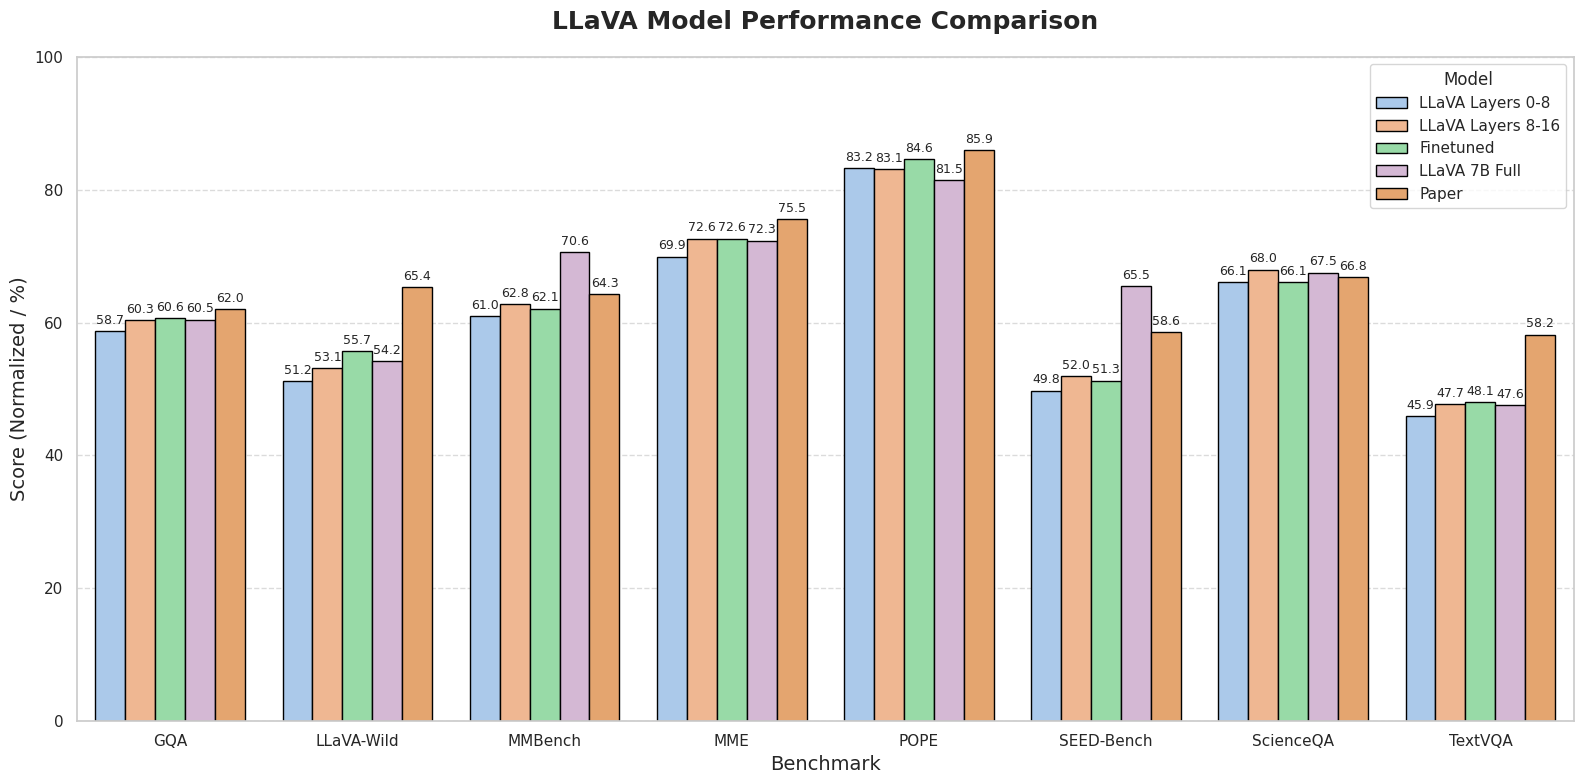

In [102]:
# Bar Plot
plt.figure(figsize=(16, 8))
plot = sns.barplot(
    data=df,
    x="Benchmark",
    y="Score_Normalized",
    hue="Model",
    palette=["#a1c9f4", "#ffb482", "#8de5a1", "#d9b3d9", "#f7a35c"],  # Blue, Orange, Green, Purple, Yellow pastel
    edgecolor="black",
    linewidth=1
)

plt.title("LLaVA Model Performance Comparison", fontsize=18, fontweight='bold', pad=20)
plt.ylabel("Score (Normalized / %)", fontsize=14)
plt.xlabel("Benchmark", fontsize=14)
plt.ylim(0, 100)
plt.legend(title="Model", title_fontsize=12, fontsize=11, loc='upper right')
plt.grid(axis='y', linestyle='--', alpha=0.7)

# Add value labels
if hasattr(plot, 'containers'):
    for container in plot.containers:
        plot.bar_label(container, fmt='%.1f', padding=3, fontsize=9)

plt.tight_layout()
plt.savefig("benchmarks_comparison.png", dpi=300)
plt.show()
